## Compare complexity measures

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
# real = pd.read_csv('../results/synthetic_stage1.csv')
# stage1 = pd.read_csv('../results/synthetic_stage1.csv')
stage2 = pd.read_csv('../results/synthetic_stage2.csv')
# stage3 = pd.read_csv('../results/synthetic_stage1.csv')

In [8]:
stage2.shape

(50000, 26)

In [10]:
stage2.head()

,id,n_classes,n_rows,n_cols,c1,c2,cls_coef,density,f1.mean,f1v.mean,...,l3.mean,lsc,n1,n2.mean,n3.mean,n4.mean,t1,t2,t3,t4
0,0,2,491,69,0.996332,0.010111,0.479150,0.869055,0.954143,NaN,...,0.199593,0.991434,0.462322,0.486404,0.346232,0.258656,0.989817,0.140530,0.091650,0.652174
1,1,8,772,24,0.993729,0.004636,0.418714,0.966543,0.935817,NaN,...,0.180662,0.997768,0.775907,0.514908,0.593264,0.700777,0.841969,0.031088,0.022021,0.708333
2,2,3,2465,1,0.996670,0.005746,0.214329,0.939274,0.991068,NaN,...,0.460332,0.999361,0.867748,NaN,0.636105,0.644219,0.734280,0.000406,0.000406,1.000000
3,3,5,3271,31,0.887108,0.096918,0.519312,0.933299,0.941512,NaN,...,0.079372,0.999192,0.624580,0.486999,0.447875,0.521859,0.814430,0.009477,0.007949,0.838710
4,4,9,6428,44,0.887119,0.072841,0.331202,0.965303,0.978634,NaN,...,0.000887,0.999786,0.847853,0.542470,0.738332,0.751556,0.978376,0.006845,0.004045,0.590909


In [11]:
def barplot(df, base):
    fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
    for ax, col in zip(axes, df.columns[1:4]):
        if col not in df:
            ax.set_visible(False); continue
        v = df[col]
        ax.hist(v, bins=30, linewidth=1)
        ax.set_title(col)
        ax.grid(axis="x", visible=False)
    fig.suptitle(f'Características dos datasets {base}', x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

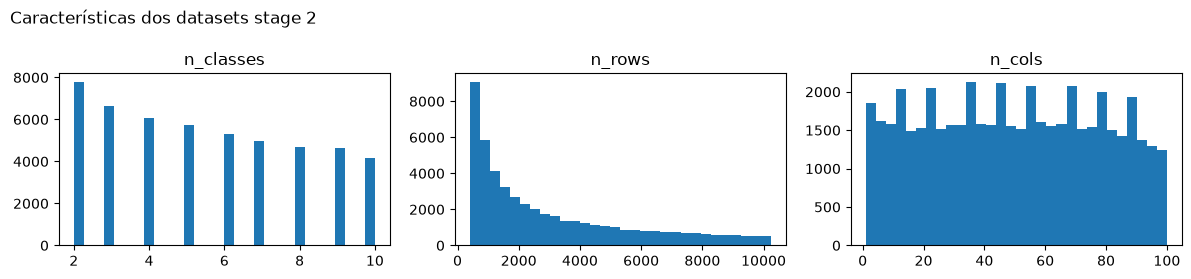

In [12]:
barplot(stage2, 'stage 2') 

In [13]:
def boxplot(df, base):
    meta = ["id", "n_classes", "n_rows", "n_cols"]
    medidas = df.drop(columns=meta).dropna(axis="columns", how="all")
    variaveis = medidas.median().sort_values().index.tolist()
    
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(variaveis)), 4))
    ax.boxplot([medidas[c].dropna() for c in variaveis])
    ax.set_xticks(
        range(1, len(variaveis) + 1), variaveis,
        rotation=60, ha="right", rotation_mode="anchor",
    )
    ax.set_ylabel("valor da medida")
    ax.set_title(f'Medidas de complexidade da base {base}')
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    plt.show()

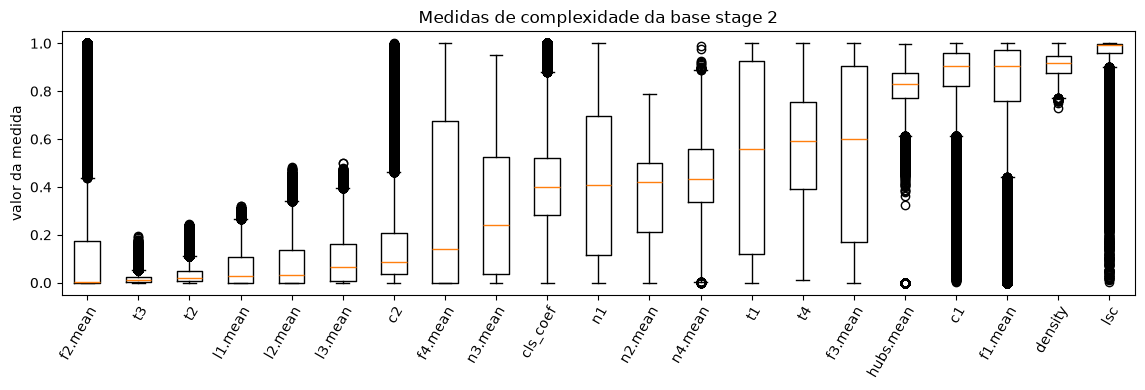

In [14]:
boxplot(stage2, 'stage 2') 

In [17]:
def heatmap(df, base):
    cols_corr = df.iloc[:, 4:].dropna(axis="columns", how="all").columns
    corr = df[cols_corr].corr(method="spearman")
    n = len(cols_corr)
    fig, ax = plt.subplots(figsize=(0.45 * n + 2.5, 0.45 * n + 1))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)     # azul = negativa, vermelho = positiva
    ax.set_xticks(range(n), cols_corr, rotation=90)
    ax.set_yticks(range(n), cols_corr)
    ax.grid(False)
    for i in range(n):
        for j in range(n):
            r = corr.iloc[i, j]
            if i != j and abs(r) >= 0.7:                          # anota só as correlações fortes
                ax.text(j, i, f"{r:.1f}", ha="center", va="center", fontsize=6,
                        color="white" if abs(r) > 0.75 else "black")
    fig.colorbar(im, ax=ax, fraction=0.04, label="correlação de Spearman")
    ax.set_title(f'Correlação entre medidas de complexidade da base {base}')
    fig.tight_layout()
    plt.show()

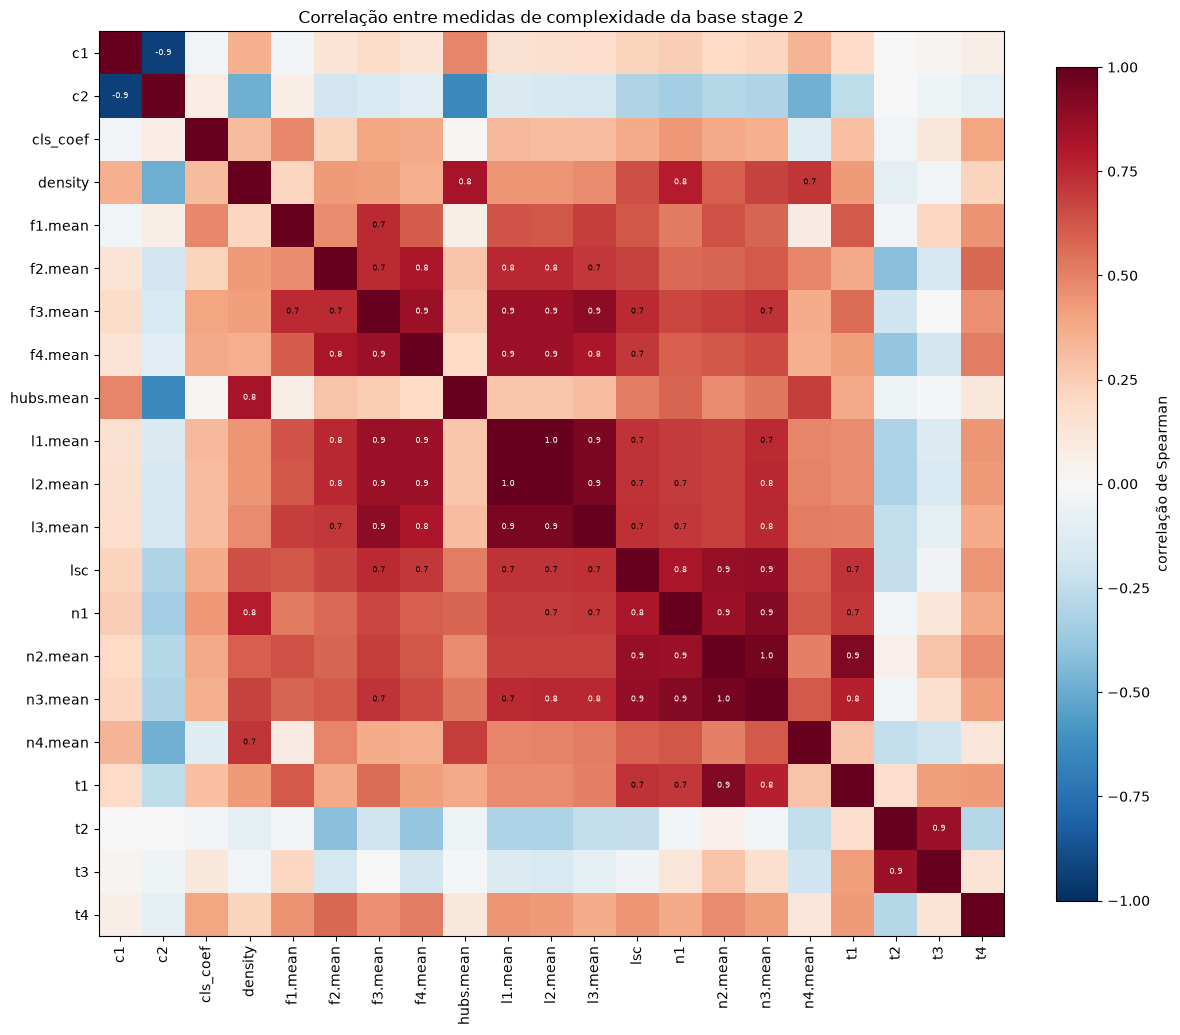

In [18]:
heatmap(stage2, 'stage 2')

In [ ]:
# Próximos passos
# - rodar na axia
# - usar o prior do tabicl v2
# - definir os hyperparametros de geração das bases
# - rodar as medias de complexidade para bases reais
# - vamos gerar dados siteticos?

# Mais comentarios
# - mais meta-features como impureza de gini (arvore)
# - usar classificadores como metricas
# - 